# Chapter 35: The landscape

Checks [chapter 35](../../book/35-the-landscape.md). Three stand-in models. (1) A **linear model in its weights**:
fixed sine and cosine features of fixed frequencies, with trained coefficients, so the output is linear in the weights.
(2) The **two-weight model** `first x second`, which is not linear in its weights. (3) **Unit arrows** in a real
vector space, for the neural-collapse geometry. No network is trained to collapse: the chapter proves only the
geometry. NumPy in float64 and PyTorch, seeded. These are measurements, not proofs: the proofs are in
`ModeConnectivity.lean` and `NeuralCollapse.lean`. Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
import torch
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
SEED = 35
generator = np.random.default_rng(SEED)


def blend(weights_one, weights_two, fraction):
    return (1.0 - fraction) * np.asarray(weights_one) + fraction * np.asarray(weights_two)


def two_weight_output(first_weight, second_weight):
    return first_weight * second_weight


def get_hill(fraction, fit_one, fit_two):
    """The chapter's hill: fraction (1 - fraction) times the product of the two differences."""
    return fraction * (1.0 - fraction) * ((fit_one[0] - fit_two[0]) * (fit_one[1] - fit_two[1]))


def make_features(inputs, frequency_count):
    """Fixed sine and cosine features: the model is linear in its coefficients."""
    frequencies = np.arange(1, frequency_count + 1)
    angles = np.outer(inputs, frequencies)
    return np.concatenate([np.sin(angles), np.cos(angles)], axis=1)

## Claim 1: a model linear in its weights has no hill (`fit_along`, `no_barrier`)

The model is `features(input) @ coefficients`, with 6 fixed sine and cosine pairs (12 coefficients) and 5 data points,
so many different coefficient vectors fit the data exactly. **Prediction:** two exact fits, one the minimum-norm
solution and one that adds a random vector from the null space of the features, are more than 1 apart; the error
along the line between them is zero at every fraction (rounding error only, below 1e-12). Second, for two arbitrary
coefficient vectors that do not fit, the error (the length of the residual vector) never exceeds the larger of the two
end errors. **Against the claim:** any fraction with an error above 1e-12 for the exact fits, or any point above the
larger end error.

In [2]:
data_inputs = np.linspace(-2.0, 2.0, 5)
data_labels = np.array([0.5, -1.0, 2.0, 0.3, -0.7])
feature_matrix = make_features(data_inputs, 6)

min_norm_fit = np.linalg.lstsq(feature_matrix, data_labels, rcond=None)[0]
_, _, right_vectors = np.linalg.svd(feature_matrix)
null_space = right_vectors[5:]                     # the 7 directions that change no output
other_fit = min_norm_fit + 3.0 * (null_space.T @ generator.standard_normal(null_space.shape[0]))

fractions = np.linspace(0.0, 1.0, 101)
linear_errors = np.array([
    np.linalg.norm(feature_matrix @ blend(min_norm_fit, other_fit, fraction) - data_labels)
    for fraction in fractions])
fits_apart = np.linalg.norm(min_norm_fit - other_fit)
report("linear model: two exact fits far apart, zero error along the whole line",
       fits_apart > 1.0 and linear_errors.max() < 1e-12,
       f"distance between the fits {fits_apart:.2f}, largest error on the line {linear_errors.max():.1e}")

worst_excess = -np.inf
for trial in range(200):
    weights_one = generator.standard_normal(12)
    weights_two = generator.standard_normal(12)
    end_error = max(np.linalg.norm(feature_matrix @ weights_one - data_labels),
                    np.linalg.norm(feature_matrix @ weights_two - data_labels))
    line_error = max(np.linalg.norm(feature_matrix @ blend(weights_one, weights_two, fraction) - data_labels)
                     for fraction in fractions)
    worst_excess = max(worst_excess, line_error - end_error)
report("linear model: the error on the line never exceeds the worse end (200 random pairs)",
       worst_excess <= 1e-12, f"largest (line error - worse end error) {worst_excess:.1e}")

[PASS] linear model: two exact fits far apart, zero error along the whole line  (distance between the fits 8.42, largest error on the line 6.3e-15)
[PASS] linear model: the error on the line never exceeds the worse end (200 random pairs)  (largest (line error - worse end error) 0.0e+00)


True

## Claim 2: with two weights multiplied, the output is the target minus the hill (`twoLayer_along`)

The model is `first x second`. Draw 300 random fits of a random target: pick the first weight (nonzero), set the second to
`target / first`. For each pair of fits and each fraction, blend the weights, multiply, and compare with
`target - fraction (1 - fraction) (difference in first)(difference in second)`. **Prediction:** agreement to rounding error
(below 1e-9) everywhere. **Against the claim:** a disagreement above 1e-9. The control sets the hill term to zero in the
formula (as for a linear model): it must then miss the measured output by a visible amount, about the size of the hill.

In [3]:
largest_gap = 0.0
largest_control_gap = 0.0
for trial in range(300):
    target = generator.uniform(-8.0, 8.0)
    fit_one_first = generator.uniform(0.3, 4.0) * generator.choice([-1.0, 1.0])
    fit_two_first = generator.uniform(0.3, 4.0) * generator.choice([-1.0, 1.0])
    fit_one = (fit_one_first, target / fit_one_first)
    fit_two = (fit_two_first, target / fit_two_first)
    for fraction in generator.uniform(0.0, 1.0, size=20):
        blended = blend(fit_one, fit_two, fraction)
        output = two_weight_output(*blended)
        formula = target - get_hill(fraction, fit_one, fit_two)
        largest_gap = max(largest_gap, abs(output - formula))
        largest_control_gap = max(largest_control_gap, abs(output - target))
report("two weights: output = target - fraction (1 - fraction) x product of differences",
       largest_gap < 1e-9, f"largest gap {largest_gap:.1e}")
report("control: dropping the hill term (the linear-model answer) misses by a lot",
       largest_control_gap > 1.0, f"largest miss {largest_control_gap:.2f}")

hand_output = two_weight_output(*blend((2.0, 3.0), (3.0, 2.0), 0.5))
hand_hill = get_hill(0.5, (2.0, 3.0), (3.0, 2.0))
report("the chapter's example: halfway between (2, 3) and (3, 2) the output is 6.25, the hill -0.25",
       abs(hand_output - 6.25) < 1e-12 and abs(hand_hill + 0.25) < 1e-12,
       f"output {hand_output}, hill {hand_hill}")

[PASS] two weights: output = target - fraction (1 - fraction) x product of differences  (largest gap 3.6e-15)
[PASS] control: dropping the hill term (the linear-model answer) misses by a lot  (largest miss 15.80)
[PASS] the chapter's example: halfway between (2, 3) and (3, 2) the output is 6.25, the hill -0.25  (output 6.25, hill -0.25)


True

## Claim 3: the mirror fit gives a hill from writing one function two ways (`twoLayer_flip`, `twoLayer_midpoint_mirror`)

If `(a, b)` fits then `(-a, -b)` fits, and halfway between them both weights are zero, so the output is zero whatever the
target. **Prediction:** over 200 random targets with magnitude at least 1, the mirror is exactly as good a fit, the
midpoint output is exactly 0, and so the squared error at the midpoint equals the target squared. **Against the claim:** a
mirror that does not fit, or a midpoint output other than zero.

In [4]:
flip_ok = True
midpoint_ok = True
squared_error_matches = True
for trial in range(200):
    target = generator.uniform(1.0, 9.0) * generator.choice([-1.0, 1.0])
    first_weight = generator.uniform(0.3, 4.0) * generator.choice([-1.0, 1.0])
    fit = (first_weight, target / first_weight)
    mirror = (-fit[0], -fit[1])
    flip_ok &= abs(two_weight_output(*mirror) - target) < 1e-9
    midpoint = blend(fit, mirror, 0.5)
    midpoint_ok &= bool(np.all(np.abs(midpoint) < 1e-12)) and two_weight_output(*midpoint) == 0.0
    squared_error_matches &= abs((two_weight_output(*midpoint) - target) ** 2 - target ** 2) < 1e-9
report("mirror (-a, -b) fits the same target, and the midpoint is (0, 0) with output 0",
       flip_ok and midpoint_ok and squared_error_matches)

[PASS] mirror (-a, -b) fits the same target, and the midpoint is (0, 0) with output 0

True

## Figure: the loss along the straight line, and along a path that stays at equal loss

Loss is the squared error. Two-weight model, target 6: the straight line from `(2, 3)` to `(3, 2)`, the straight line
from `(2, 3)` to its mirror `(-2, -3)`, and (not proved in the chapter, drawn for contrast) the curve of
weights `(a, 6 / a)` for `a` from 2 to 3, which leaves the set of fits nowhere. Beside them, the linear model of
claim 1 along its straight line. **Prediction:** the first straight line peaks at 0.0625 halfway, the mirror line
peaks at 36 halfway, and the other paths stay at zero, to rounding error. The measured values are the lines, and the
exact formula (the hill, squared) is drawn as dots on the same axes.

[PASS] measured squared error on the two straight lines equals the proved hill squared  (swap peak 0.0625 at fraction 0.50, mirror peak 36.00 at 0.50)
[PASS] the curved path and the linear-model line stay at zero loss  (curve 7.9e-31, linear 4.1e-29)


wrote book/figures/35-hill-along-the-line.png


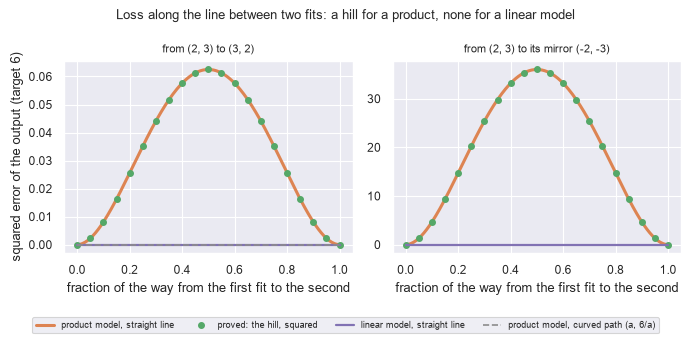

In [5]:
TARGET = 6.0
fit_near, fit_far, fit_mirror = (2.0, 3.0), (3.0, 2.0), (-2.0, -3.0)
fine_fractions = np.linspace(0.0, 1.0, 201)


def measure_squared_error_on_line(fit_one, fit_two):
    return np.array([(two_weight_output(*blend(fit_one, fit_two, fraction)) - TARGET) ** 2
                     for fraction in fine_fractions])


swap_loss = measure_squared_error_on_line(fit_near, fit_far)
mirror_loss = measure_squared_error_on_line(fit_near, fit_mirror)
swap_formula = np.array([get_hill(fraction, fit_near, fit_far) ** 2 for fraction in fine_fractions])
mirror_formula = np.array([get_hill(fraction, fit_near, fit_mirror) ** 2 for fraction in fine_fractions])
curve_first = (1.0 - fine_fractions) * 2.0 + fine_fractions * 3.0
curve_loss = (curve_first * (TARGET / curve_first) - TARGET) ** 2
linear_loss = np.array([np.linalg.norm(feature_matrix @ blend(min_norm_fit, other_fit, fraction) - data_labels) ** 2
                        for fraction in fine_fractions])

report("measured squared error on the two straight lines equals the proved hill squared",
       np.abs(swap_loss - swap_formula).max() < 1e-9 and np.abs(mirror_loss - mirror_formula).max() < 1e-9,
       f"swap peak {swap_loss.max():.4f} at fraction {fine_fractions[swap_loss.argmax()]:.2f}, "
       f"mirror peak {mirror_loss.max():.2f} at {fine_fractions[mirror_loss.argmax()]:.2f}")
report("the curved path and the linear-model line stay at zero loss",
       curve_loss.max() < 1e-20 and linear_loss.max() < 1e-20,
       f"curve {curve_loss.max():.1e}, linear {linear_loss.max():.1e}")

figure, (left_axis, right_axis) = plt.subplots(1, 2, figsize=(7.0, 3.3))
for axis, straight_loss, formula, title, draw_curve in (
        (left_axis, swap_loss, swap_formula, "from (2, 3) to (3, 2)", True),
        (right_axis, mirror_loss, mirror_formula, "from (2, 3) to its mirror (-2, -3)", False)):
    axis.plot(fine_fractions, straight_loss, color=VERTICAL, linewidth=2.2, label="product model, straight line")
    axis.plot(fine_fractions[::10], formula[::10], linestyle="none", marker="o", markersize=4, color=BOUND,
              label="proved: the hill, squared")
    axis.plot(fine_fractions, linear_loss, color=MODEL, linewidth=1.6, label="linear model, straight line")
    if draw_curve:
        axis.plot(fine_fractions, curve_loss, color=BEFORE, linewidth=1.2, linestyle="--",
                  label="product model, curved path (a, 6/a)")
    axis.set_title(title, fontsize=8)
    axis.set_xlabel("fraction of the way from the first fit to the second")
left_axis.set_ylabel("squared error of the output (target 6)")
figure.suptitle("Loss along the line between two fits: a hill for a product, none for a linear model", fontsize=9)
handles, labels = left_axis.get_legend_handles_labels()
figure.legend(handles, labels, loc="lower center", ncol=4, fontsize=6.5)
figure.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(figure, "35-hill-along-the-line")
plt.show()

## Claim 4: arrows of length one cannot all overlap by less than `-1 / (classes - 1)` (`neg_one_le_of_inner_le`)

First the identity behind the proof (`norm_sum_sq_eq_sum_inner`): for any unit arrows the squared length of their sum is
`classes` plus the sum of the overlaps of every ordered pair of different arrows. Then the limit. For each class count from
2 to 10 we search for unit arrows in `classes` dimensions whose **largest overlap is as low as possible**, by gradient
descent on a smooth maximum (log-sum-exp with a rising sharpness) from 30 random starts each, and compare the best result
with `-1 / (classes - 1)`. **Prediction:** no search result goes below `-1 / (classes - 1)` (up to 1e-9), the best result
gets within 1e-3 of it, and the arrows of the best result add up to nearly zero (the simplex, `sum_eq_zero_iff_of_equiangular`).
**Against the claim:** a configuration of unit arrows below the limit. The control uses arrows of length 1.5, which breaks
the hypothesis: the regular simplex of such arrows has every overlap `-2.25 / (classes - 1)`, which is below the
unit-length limit, so the conclusion must fail, and by how much is reported.

In [6]:
def get_overlaps(arrows):
    """All overlaps of pairs of different arrows, as a flat list with the diagonal removed."""
    overlap_matrix = arrows @ arrows.T
    mask = ~np.eye(len(arrows), dtype=bool)
    return overlap_matrix[mask]


# the identity behind the proof
identity_gap = 0.0
for trial in range(100):
    class_count = int(generator.integers(2, 9))
    arrows = generator.standard_normal((class_count, 5))
    arrows /= np.linalg.norm(arrows, axis=1, keepdims=True)
    squared_length = np.linalg.norm(arrows.sum(axis=0)) ** 2
    identity_gap = max(identity_gap, abs(squared_length - (class_count + get_overlaps(arrows).sum())))
report("squared length of the sum = classes + sum of pair overlaps", identity_gap < 1e-9, f"largest gap {identity_gap:.1e}")


def search_lowest_largest_overlap(class_count, restarts=30, steps=1500):
    """Gradient descent on the log-sum-exp of the overlaps of unit arrows, all restarts at once;
    returns the best arrows found. Adam treats every parameter separately, so restarts do not interact."""
    torch.manual_seed(SEED + class_count)
    mask = ~torch.eye(class_count, dtype=torch.bool)
    raw = torch.randn(restarts, class_count, class_count, dtype=torch.float64, requires_grad=True)
    optimiser = torch.optim.Adam([raw], lr=0.03)
    for step in range(steps):
        sharpness = 5.0 + 295.0 * step / steps
        unit = raw / raw.norm(dim=2, keepdim=True)
        overlaps = (unit @ unit.transpose(1, 2))[:, mask]
        loss = (torch.logsumexp(sharpness * overlaps, dim=1) / sharpness).sum()
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
    unit = (raw / raw.norm(dim=2, keepdim=True)).detach().numpy()
    values = np.array([get_overlaps(restart_arrows).max() for restart_arrows in unit])
    return unit[values.argmin()], values.min()


CLASS_COUNTS = list(range(2, 11))
found_values, limits, sum_lengths, random_values = [], [], [], []
for class_count in CLASS_COUNTS:
    arrows, value = search_lowest_largest_overlap(class_count)
    found_values.append(value)
    limits.append(-1.0 / (class_count - 1))
    sum_lengths.append(np.linalg.norm(arrows.sum(axis=0)))
    random_arrows = generator.standard_normal((2000, class_count, class_count))
    random_arrows /= np.linalg.norm(random_arrows, axis=2, keepdims=True)
    random_overlap_max = np.array([get_overlaps(sample).max() for sample in random_arrows])
    random_values.append(random_overlap_max.min())

found_values, limits, sum_lengths, random_values = map(np.array, (found_values, limits, sum_lengths, random_values))
report("no search result is below -1 / (classes - 1), and the best reach it",
       bool(np.all(found_values >= limits - 1e-9)) and bool(np.all(found_values - limits < 1e-3)),
       f"smallest margin above the limit {np.min(found_values - limits):.1e}, largest {np.max(found_values - limits):.1e}")
report("the best arrangements add up to nearly zero",
       bool(np.all(sum_lengths < 1e-2)), f"largest length of the sum {sum_lengths.max():.1e}")
report("no random arrangement (2000 per class count) is below the limit either",
       bool(np.all(random_values >= limits - 1e-9)),
       f"smallest gap above the limit over class counts {np.min(random_values - limits):.3f}")

CONTROL_LENGTH = 1.5
control_overlaps = CONTROL_LENGTH ** 2 * limits             # the simplex of length-1.5 arrows
centred = np.eye(4) - 0.25
centred /= np.linalg.norm(centred, axis=1, keepdims=True)
explicit_overlap = get_overlaps(CONTROL_LENGTH * centred).max()
report("control: arrows of length 1.5 go below the unit-length limit",
       bool(np.all(control_overlaps < limits)) and abs(explicit_overlap - control_overlaps[2]) < 1e-12,
       f"for 4 classes the largest overlap is {explicit_overlap:.3f}, the unit limit is {limits[2]:.3f}, "
       f"a miss of {limits[2] - explicit_overlap:.3f}")

[PASS] squared length of the sum = classes + sum of pair overlaps  (largest gap 3.6e-15)


[PASS] no search result is below -1 / (classes - 1), and the best reach it  (smallest margin above the limit -2.2e-16, largest 6.5e-04)
[PASS] the best arrangements add up to nearly zero  (largest length of the sum 1.3e-03)
[PASS] no random arrangement (2000 per class count) is below the limit either  (smallest gap above the limit over class counts 0.000)
[PASS] control: arrows of length 1.5 go below the unit-length limit  (for 4 classes the largest overlap is -0.750, the unit limit is -0.333, a miss of 0.417)


True

## Figure: the lowest largest overlap against the number of classes

Drawn: the best largest overlap found by the search, the best of 2000 random unit arrangements, the proved limit
`-1 / (classes - 1)` and the length-1.5 control. **Prediction:** the search points sit on the limit, the random points
sit above it, and the control sits below it. Every plotted number is from the cells above.

wrote book/figures/35-class-overlap-limit.png


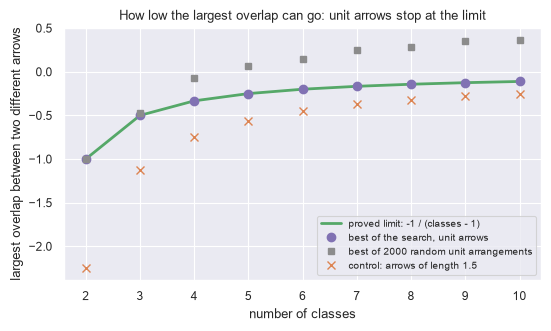

In [7]:
figure, axis = plt.subplots(figsize=(5.6, 3.4))
axis.plot(CLASS_COUNTS, limits, color=BOUND, linewidth=2.0, label="proved limit: -1 / (classes - 1)")
axis.plot(CLASS_COUNTS, found_values, linestyle="none", marker="o", markersize=6, color=MODEL,
          label="best of the search, unit arrows")
axis.plot(CLASS_COUNTS, random_values, linestyle="none", marker="s", markersize=4, color=BEFORE,
          label="best of 2000 random unit arrangements")
axis.plot(CLASS_COUNTS, control_overlaps, linestyle="none", marker="x", markersize=6, color=VERTICAL,
          label="control: arrows of length 1.5")
axis.set_xlabel("number of classes")
axis.set_ylabel("largest overlap between two different arrows")
axis.set_title("How low the largest overlap can go: unit arrows stop at the limit")
axis.legend(fontsize=7)
figure.tight_layout()
save_figure(figure, "35-class-overlap-limit")
plt.show()

## Check yourself, by computation

Question 1: the output halfway between `(1, 6)` and `(3, 2)` for `first x second`; question 2: the limit for five classes;
question 3: the error a third of the way between two exact fits of a linear model. Each is computed here.

In [8]:
halfway = blend((1.0, 6.0), (3.0, 2.0), 0.5)
halfway_output = two_weight_output(*halfway)
formula_output = 6.0 - get_hill(0.5, (1.0, 6.0), (3.0, 2.0))
five_class_limit = -1.0 / (5 - 1)
third_error = np.linalg.norm(feature_matrix @ blend(min_norm_fit, other_fit, 1.0 / 3.0) - data_labels)
report("answers to the three check-yourself questions",
       abs(halfway_output - formula_output) < 1e-12 and third_error < 1e-12,
       f"(1) halfway weights {halfway}, output {halfway_output}; (2) five classes {five_class_limit}; (3) error {third_error:.1e}")

[PASS] answers to the three check-yourself questions  ((1) halfway weights [2. 4.], output 8.0; (2) five classes -0.25; (3) error 3.3e-15)


True